# Airbnb NYC 2019 Dataset

This dataset contains information on various Airbnb listings during 2019. 
It includes details such as the borough, the price, the exact location, the amount of time listed, etc.

In [11]:
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
df = pd.read_csv("AB_NYC_2019.csv")

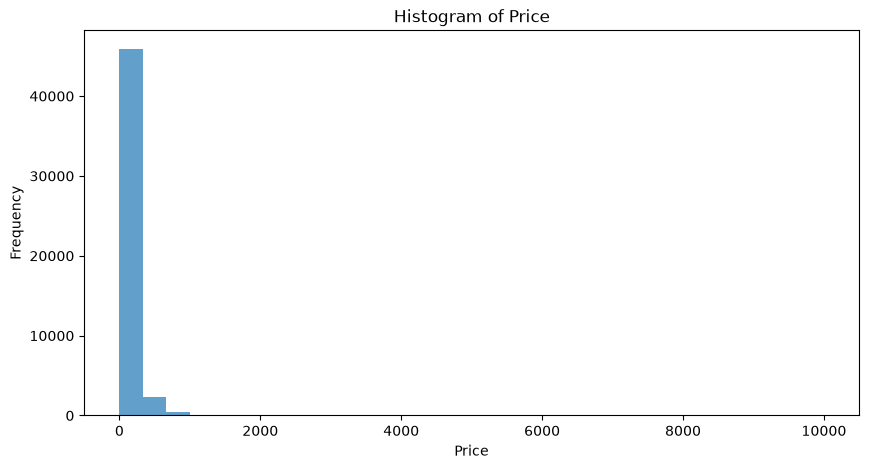

In [10]:
# Pirce Histogram
plt.figure(figsize=(10, 5))
df['price'].plot(kind='hist', bins=30, alpha=0.7)
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.title('Histogram of Price')
plt.show()

In [4]:
# Log + 1 transformation for price
import numpy as np
df['normalized_price'] = np.log1p(df['price'])

count    48895.000000
mean         4.736885
std          0.695344
min          0.000000
25%          4.248495
50%          4.672829
75%          5.170484
max          9.210440
Name: normalized_price, dtype: float64


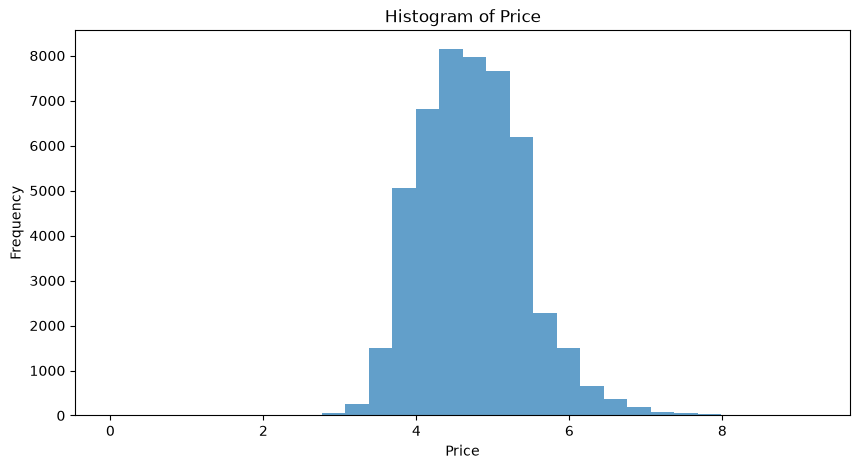

In [5]:
# Price Histogram (Normalized)
print(df['normalized_price'].describe())
plt.figure(figsize=(10, 5))
df['normalized_price'].plot(kind='hist', bins=30, alpha=0.7)
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.title('Histogram of Price')
plt.show()


In [16]:
import ipywidgets as widgets
from matplotlib.ticker import FuncFormatter

# Price by Neighbourhood
neighbourhoods = df['neighbourhood_group'].unique()

neighbourhood_dropdown = widgets.Dropdown(
    options=neighbourhoods,
    description='Neighbourhood:',
)

def plot_price_by_neighbourhood(neighbourhood):
    plt.figure(figsize=(10, 5))
    ax = plt.gca()
    df[df['neighbourhood_group'] == neighbourhood]['normalized_price'].plot(
        kind='hist', bins=30, alpha=0.7, ax=ax
    )
    plt.xlabel('Price ($)')
    plt.ylabel('Frequency')
    plt.title(f'Histogram of Normalized Price in {neighbourhood}')
    plt.show()
widgets.interact(plot_price_by_neighbourhood, neighbourhood=neighbourhood_dropdown)


interactive(children=(Dropdown(description='Neighbourhood:', options=('Brooklyn', 'Manhattan', 'Queens', 'Stat…

<function __main__.plot_price_by_neighbourhood(neighbourhood)>

# Airbnb location heatmap

This set of plots shows how Airbnb prices are distributed in New York. 
The interactive widget allows you to view how the price distribution changes across each of the boroughs.

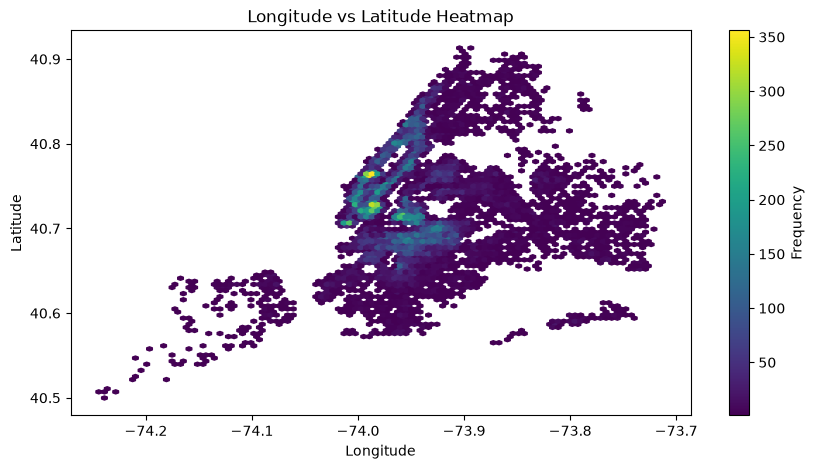

In [17]:
# Longitude Lattitude Heatmap
plt.figure(figsize=(10, 5))
plt.hexbin(df['longitude'], df['latitude'], gridsize=100, cmap='viridis', mincnt=1)
plt.colorbar(label='Frequency')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Longitude vs Latitude Heatmap')
plt.show()

In [18]:
# Per Borough Heatmap widget
boroughs = df['neighbourhood_group'].unique()
def plot_heatmap_by_borough(borough):
    plt.figure(figsize=(10, 5))
    subset = df[df['neighbourhood_group'] == borough]
    plt.hexbin(subset['longitude'], subset['latitude'], gridsize=100, cmap='viridis', mincnt=1)
    plt.colorbar(label='Frequency')
    plt.xlabel('Longitude')
    plt.ylabel('Latitude')
    plt.title(f'Longitude vs Latitude Heatmap in {borough}')
    plt.show()

widgets.interact(plot_heatmap_by_borough, borough=boroughs)

interactive(children=(Dropdown(description='borough', options=('Brooklyn', 'Manhattan', 'Queens', 'Staten Isla…

<function __main__.plot_heatmap_by_borough(borough)>

# Airbnb location heatmap

This set of plots shows how Airbnbs are distributed in New York. 
The interactive widget allows you to view the spread in each of the boroughs.